# DACS-SCV v3: transparency-safe resumable formal SciVer runner

This notebook installs the background package from a writable directory, checks the public release, executes the frozen five-seed formal protocol, and packages every audit artifact. The default is the **formal run on Kaggle** and a **synthetic smoke run elsewhere**. Version 3 correctly composites transparent scientific figures onto white before perceptual auditing and CLIP encoding, while preserving downloads, features, and checkpoints in persistent `/kaggle/working` locations. The formal archive still requires independent audit before its values enter the paper.

## 1. Parameters

The local development pilots and protocol audit are complete. On Kaggle, leave `PROFILE='formal'` unchanged. Before running, add a private Kaggle secret named `HF_TOKEN` containing a free Hugging Face **read-only** token; the notebook reads it without printing it. Formal mode uses all eligible public SciVer development records, five predetermined seeds, frozen BGE/CLIP features, and 10,000 source-paper-grouped bootstrap samples on the official test. Do not rerun with altered settings after viewing the test output.

In [1]:
from pathlib import Path
import json
import os
import shutil
import subprocess
import sys
import zipfile

INPUT_ROOT = Path(os.environ.get('TRACE_SCV_INPUT_ROOT', '/kaggle/input'))
WORKING_ROOT = Path(os.environ.get('TRACE_SCV_WORKING_ROOT', '/kaggle/working'))
IS_KAGGLE = os.environ.get('TRACE_SCV_FORCE_KAGGLE') == '1' or Path('/kaggle/input').exists()
PROFILE = os.environ.get('TRACE_SCV_PROFILE', 'formal' if IS_KAGGLE else 'smoke')  # smoke | formal
DOWNLOAD_PUBLIC_DATA = PROFILE != 'smoke'
DEVICE = 'auto'
EXPECTED_VERSION = '0.3.2'
DATA_ROOT = Path(os.environ.get('TRACE_SCV_DATA_ROOT', WORKING_ROOT / 'dacs-scv-data-v2'))
OUTPUT_ROOT = Path(os.environ.get('TRACE_SCV_OUTPUT_ROOT', WORKING_ROOT / 'dacs-scv-outputs-v2'))
os.environ['TRACE_SCV_DATA_ROOT'] = str(DATA_ROOT)
os.environ['TRACE_SCV_OUTPUT_ROOT'] = str(OUTPUT_ROOT)
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')
os.environ.setdefault('HF_HUB_DOWNLOAD_TIMEOUT', '600')
os.environ.setdefault('HF_HUB_ETAG_TIMEOUT', '120')
os.environ.setdefault('TRACE_SCV_HF_RETRIES', '5')
os.environ.setdefault('TRACE_SCV_HF_WORKERS', '2')

if IS_KAGGLE and not os.environ.get('HF_TOKEN'):
    try:
        from kaggle_secrets import UserSecretsClient
        secret_token = UserSecretsClient().get_secret('HF_TOKEN')
        if secret_token:
            os.environ['HF_TOKEN'] = secret_token
    except Exception:
        pass
run_configuration = {
    'profile': PROFILE,
    'download': DOWNLOAD_PUBLIC_DATA,
    'kaggle': IS_KAGGLE,
    'hf_authenticated': bool(os.environ.get('HF_TOKEN')),
    'resumable_data_root': str(DATA_ROOT),
    'resumable_output_root': str(OUTPUT_ROOT),
}
print(run_configuration)
if IS_KAGGLE and PROFILE == 'formal' and not os.environ.get('HF_TOKEN'):
    raise RuntimeError(
        'Missing Kaggle secret HF_TOKEN. Add a free Hugging Face read-only token '
        'under Add-ons > Secrets, enable it for this notebook, restart the session, '
        'and choose Run All. Do not paste the token into a cell.'
    )

{'profile': 'formal', 'download': True, 'kaggle': True, 'hf_authenticated': True, 'resumable_data_root': '/kaggle/working/dacs-scv-data-v2', 'resumable_output_root': '/kaggle/working/dacs-scv-outputs-v2'}


## 2. Locate and install the code

Kaggle inputs are read-only. This setup validates the uploaded source, copies or extracts it to `/kaggle/working`, installs it non-editably, and then pins Python to that exact source tree. The pin and module-cache reset prevent an older `trace_scv` package from shadowing the uploaded code.

In [2]:
REQUIRED_SOURCE_FILES = (
    Path('experiments/pyproject.toml'),
    Path('experiments/src/trace_scv/data/__init__.py'),
    Path('experiments/src/trace_scv/data/preflight.py'),
    Path('experiments/src/trace_scv/cardinality.py'),
    Path('experiments/src/trace_scv/models/cardinality.py'),
    Path('experiments/src/trace_scv/pipeline.py'),
)

def valid_repository(candidate: Path) -> bool:
    if not all((candidate / relative).is_file() for relative in REQUIRED_SOURCE_FILES):
        return False
    version_file = candidate / 'experiments/src/trace_scv/__init__.py'
    return f'__version__ = "{EXPECTED_VERSION}"' in version_file.read_text(encoding='utf-8')

def repository_roots_below(search_root: Path) -> list[Path]:
    if not search_root.exists():
        return []
    roots = []
    for marker in search_root.rglob('pyproject.toml'):
        if marker.parent.name != 'experiments':
            continue
        candidate = marker.parent.parent
        if valid_repository(candidate):
            roots.append(candidate.resolve())
    return sorted(set(roots), key=lambda path: str(path), reverse=True)

def safely_extract(archive_path: Path, destination: Path) -> None:
    with zipfile.ZipFile(archive_path) as handle:
        destination_root = destination.resolve()
        for member in handle.infolist():
            target = (destination / member.filename).resolve()
            if target != destination_root and destination_root not in target.parents:
                raise RuntimeError(f'Unsafe ZIP member in {archive_path}: {member.filename}')
        handle.extractall(destination)

def find_repository() -> Path:
    for candidate in (Path.cwd(), Path.cwd().parent):
        if valid_repository(candidate):
            return candidate.resolve()
    for candidate in repository_roots_below(INPUT_ROOT):
        print('Selected source directory:', candidate)
        return candidate
    if INPUT_ROOT.exists():
        archives = sorted(
            (path for path in INPUT_ROOT.rglob('*') if path.is_file() and path.suffix.lower() == '.zip' and 'public-data' not in path.name.lower()),
            key=lambda path: str(path),
            reverse=True,
        )
        for archive_path in archives:
            if not zipfile.is_zipfile(archive_path):
                continue
            extracted = WORKING_ROOT / 'dacs-scv-source-v3'
            if extracted.exists():
                shutil.rmtree(extracted)
            extracted.mkdir(parents=True, exist_ok=True)
            safely_extract(archive_path, extracted)
            extracted_roots = repository_roots_below(extracted)
            if extracted_roots:
                print('Selected archive:', archive_path)
                return extracted_roots[0]
    visible = []
    if INPUT_ROOT.exists():
        visible = sorted(
            str(path.relative_to(INPUT_ROOT))
            for path in INPUT_ROOT.rglob('*')
            if path.is_file()
        )[:80]
    raise FileNotFoundError(
        f'No complete DACS-SCV v3 ({EXPECTED_VERSION}) upload was found under '
        f'{INPUT_ROOT}. Visible files (first 80): {visible}'
    )

source_root = find_repository()

def repository_copy_ignore(directory: str, names: list[str]) -> set[str]:
    # Ignore generated artifacts everywhere, but ignore experiments/data only
    # at that exact level. Never ignore trace_scv/data, which is source code.
    ignored = {name for name in names if name in {'.git', '.venv', '.pytest_cache', '__pycache__', 'outputs', 'build'} or name.endswith('.egg-info')}
    if Path(directory).resolve() == (source_root / 'experiments').resolve():
        ignored.add('data')
    return ignored

try:
    source_root.relative_to(INPUT_ROOT.resolve())
    source_is_read_only_input = True
except ValueError:
    source_is_read_only_input = False
if source_is_read_only_input:
    repo_root = WORKING_ROOT / 'dacs-scv'
    if repo_root.exists():
        shutil.rmtree(repo_root)
    shutil.copytree(source_root, repo_root, ignore=repository_copy_ignore)
else:
    repo_root = source_root
package_root = repo_root / 'experiments'
missing = [str(relative) for relative in REQUIRED_SOURCE_FILES if not (repo_root / relative).is_file()]
assert not missing, f'Incomplete DACS-SCV upload; missing: {missing}'
print('Repository:', repo_root)

Selected source directory: /kaggle/input/datasets/sabbir234/dacsv3-1
Repository: /kaggle/working/dacs-scv


In [3]:
import importlib

extras = 'formal,analysis' if PROFILE in {'pilot', 'formal'} else 'ml,data,analysis'
subprocess.run([
    sys.executable, '-m', 'pip', 'install', '--quiet', '--disable-pip-version-check',
    '--upgrade-strategy', 'only-if-needed', f'{package_root}[{extras}]'
], check=True)

# A restarted Kaggle kernel may retain an older TRACE-SCV module. Import the
# uploaded source explicitly and clear every cached submodule before preflight.
source_dir = (package_root / 'src').resolve()
sys.path = [entry for entry in sys.path if Path(entry or '.').resolve() != source_dir]
sys.path.insert(0, str(source_dir))
for module_name in list(sys.modules):
    if module_name == 'trace_scv' or module_name.startswith('trace_scv.'):
        del sys.modules[module_name]
importlib.invalidate_caches()
import trace_scv
loaded_package = Path(trace_scv.__file__).resolve().parent
expected_package = source_dir / 'trace_scv'
assert loaded_package == expected_package, (loaded_package, expected_package)
assert (loaded_package / 'data' / 'preflight.py').is_file()
assert trace_scv.__version__ == EXPECTED_VERSION, (trace_scv.__version__, EXPECTED_VERSION)
print('DACS-SCV import verified:', loaded_package)
print('Any dopamine-rl/gym resolver warning above is from Kaggle preinstalled packages; DACS-SCV does not import either package.')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


DACS-SCV import verified: /kaggle/working/dacs-scv/experiments/src/trace_scv
Any dopamine-rl/gym resolver warning above is from Kaggle preinstalled packages; DACS-SCV does not import either package.


## 3. Verify public releases

In [4]:
from trace_scv.data.preflight import run_preflight
preflight = run_preflight()
assert preflight['status'] == 'pass', preflight
[(row['name'], row['accessible'], row.get('revision')) for row in preflight['datasets']]

[('SciVer', True, '5695ac384d247ae5df2a7b73568dc63d189296b0'),
 ('MuSciClaims', True, '9134142d05fb473e0a10c4c05f0c2d5a2af51099'),
 ('MOCHEG', True, '2023-11-24T22:09:09Z'),
 ('AIChartClaim', True, '2026-06-19T23:57:10Z')]

## 4. Run the experiment

The runner performs normalization, dual-channel semantic/visual feature construction, base-verifier training, frozen-ranking fixed-budget comparisons, decoupled cardinality training, official-test inference, grouped bootstrap comparisons, and output export.

In [5]:
from trace_scv.pipeline import run_pipeline
audit_dir = OUTPUT_ROOT / PROFILE / 'audit'
audit_dir.mkdir(parents=True, exist_ok=True)
(audit_dir / 'preflight.json').write_text(json.dumps(preflight, indent=2), encoding='utf-8')
result = run_pipeline(repo_root, profile=PROFILE, download=DOWNLOAD_PUBLIC_DATA, device=DEVICE)
{'summary': result['summary'], 'pilot_readiness_gate': result.get('pilot_readiness_gate')}

README.md: 0.00B [00:00, ?B/s]

valset.json: 0.00B [00:00, ?B/s]

testset.json: 0.00B [00:00, ?B/s]

Fetching 2590 files:   0%|          | 0/2590 [00:00<?, ?it/s]

2409.00049v2-Table3-1.png:   0%|          | 0.00/68.4k [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

{'summary': {'majority': {'runs': 1,
   'verdict_macro_f1_mean': 0.332220367278798,
   'citation_macro_f1_mean': 0.0,
   'citation_count_mae_mean': 1.6215,
   'citation_count_exact_match_mean': 0.0,
   'comprehensiveness_mean': 0.0,
   'gold_evidence_comprehensiveness_mean': 0.0,
   'duplicate_invariance_mean': 1.0,
   'swap_sensitivity_mean': 0.0,
   'swap_coverage_mean': 0.0,
   'visual_removed_macro_f1_mean': 0.332220367278798,
   'visual_grounded_count_mean': 996.0,
   'visual_grounded_clean_verdict_macro_f1_mean': 0.33511348464619495,
   'visual_grounded_visual_removed_macro_f1_mean': 0.33511348464619495,
   'visual_grounded_swap_sensitivity_mean': 0.0},
  'claim_only': {'runs': 5,
   'verdict_macro_f1_mean': 0.501610347821401,
   'citation_macro_f1_mean': 0.0,
   'citation_count_mae_mean': 1.6215,
   'citation_count_exact_match_mean': 0.0,
   'comprehensiveness_mean': 0.0,
   'gold_evidence_comprehensiveness_mean': 0.0,
   'duplicate_invariance_mean': 1.0,
   'swap_sensitivity_me

## 5. Review bounded results

In [6]:
import pandas as pd
summary = pd.DataFrame(result['summary']).T.reset_index(names='variant')
summary.round(4)

,variant,runs,verdict_macro_f1_mean,citation_macro_f1_mean,citation_count_mae_mean,citation_count_exact_match_mean,comprehensiveness_mean,gold_evidence_comprehensiveness_mean,duplicate_invariance_mean,swap_sensitivity_mean,swap_coverage_mean,visual_removed_macro_f1_mean,visual_grounded_count_mean,visual_grounded_clean_verdict_macro_f1_mean,visual_grounded_visual_removed_macro_f1_mean,visual_grounded_swap_sensitivity_mean
0,majority,1.0,0.3322,0.0000,1.6215,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.3322,996.0,0.3351,0.3351,0.0000
1,claim_only,5.0,0.5016,0.0000,1.6215,0.0000,0.0000,0.0000,1.0000,0.0000,0.4975,0.5016,996.0,0.5145,0.5145,0.0000
2,all_pool,5.0,0.5076,0.2464,9.8350,0.0000,0.0030,-0.0003,0.9873,0.0097,0.4975,0.5070,996.0,0.5222,0.5212,0.0097
3,relevance,5.0,0.5079,0.2811,1.4195,0.0605,0.0018,-0.0007,0.9873,0.0459,0.4975,0.5062,996.0,0.5258,0.5224,0.0459
4,flat,5.0,0.5028,0.4550,1.4195,0.0605,-0.0026,-0.0032,0.9746,0.0458,0.4975,0.5029,996.0,0.5130,0.5129,0.0458
5,trace_no_cf,5.0,0.5112,0.4569,1.4195,0.0605,0.0014,-0.0005,0.9840,0.0423,0.4975,0.5068,996.0,0.5130,0.5089,0.0423
6,fixed_top1,5.0,0.5112,0.4636,0.6215,0.4755,NaN,-0.0005,0.9840,0.0423,0.4975,0.5068,996.0,0.5130,0.5089,0.0423
7,fixed_top2,5.0,0.5112,0.4810,0.5725,0.4480,NaN,-0.0005,0.9840,0.0423,0.4975,0.5068,996.0,0.5130,0.5089,0.0423
8,dacs_scv,5.0,0.5112,0.4702,0.4954,0.5565,NaN,-0.0005,0.9840,0.0423,0.4975,0.5068,996.0,0.5130,0.5089,0.0423
9,dacs_no_valid_count,5.0,0.5112,0.4747,0.5364,0.5137,NaN,-0.0005,0.9840,0.0423,0.4975,0.5068,996.0,0.5130,0.5089,0.0423


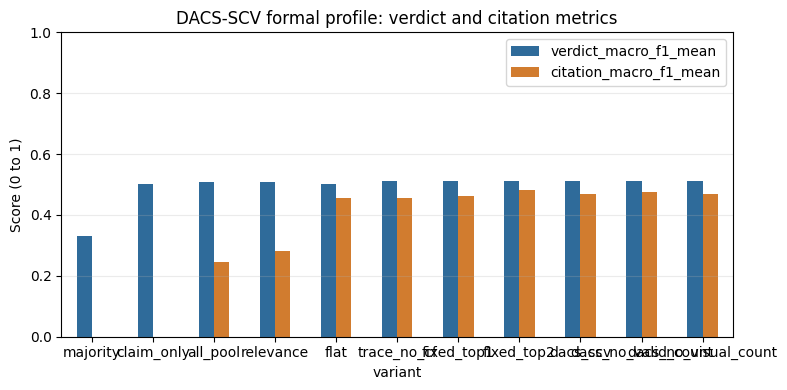

In [7]:
import matplotlib.pyplot as plt
plot = summary.set_index('variant')[['verdict_macro_f1_mean', 'citation_macro_f1_mean']].plot(kind='bar', figsize=(8, 4), color=['#2f6b9a', '#d17c2f'])
plot.set_title(f'DACS-SCV {PROFILE} profile: verdict and citation metrics')
plot.set_ylabel('Score (0 to 1)')
plot.set_ylim(0, 1)
plot.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Export outputs

The ZIP contains preflight and dataset manifests, cross-split duplicate records, input/code/configuration hashes, base and cardinality checkpoints, complete rankings, predictions, per-claim comparison records, grouped bootstrap comparisons, an artifact inventory, and the aggregate summary. Return the formal ZIP for independent audit before copying any number into the manuscript.

In [8]:
output_dir = OUTPUT_ROOT / PROFILE
archive_base = WORKING_ROOT / f'dacs-scv-{PROFILE}-outputs' if IS_KAGGLE else repo_root / f'dacs-scv-{PROFILE}-outputs'
archive = Path(shutil.make_archive(str(archive_base), 'zip', output_dir))
print('Output archive:', archive)
print('Scientific validation flag:', result['scientific_results_validated'])

Output archive: /kaggle/working/dacs-scv-formal-outputs.zip
Scientific validation flag: False


## 7. Interpretation

- `smoke`: validates software behavior only.
- `smoke`: synthetic software validation only; it is never scientific evidence.
- `formal`: executes the single frozen public-data matrix. Audit its manifests, predictions, ranking/verdict identity checks, and uncertainty outputs before transferring any number into the paper.